In [ ]:
from google.colab import files

uploaded = files.upload()

Saving netflix_customer_churn.csv to netflix_customer_churn.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("netflix_customer_churn.csv")

In [ ]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [ ]:
df.shape

(5000, 14)

In [ ]:
df.columns

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), object(7)
memor

In [ ]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [ ]:
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
subscription_type,0
watch_hours,0
last_login_days,0
region,0
device,0
monthly_fee,0
churned,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["churned"].value_counts()

,count
churned,
1,2515
0,2485


In [ ]:
df["churned"].value_counts(normalize=True) * 100

,proportion
churned,
1,50.3
0,49.7


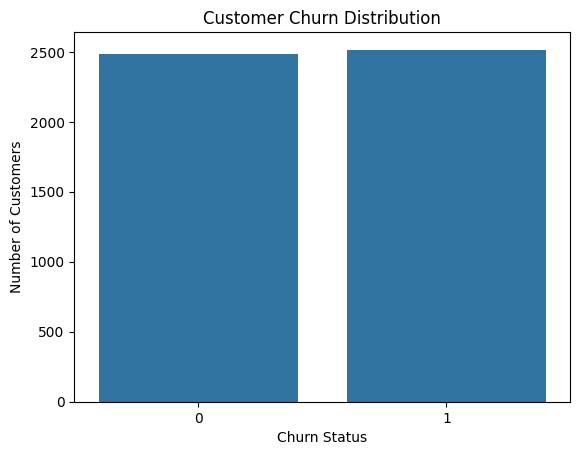

In [ ]:
sns.countplot(data=df, x="churned")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

2. Visualization

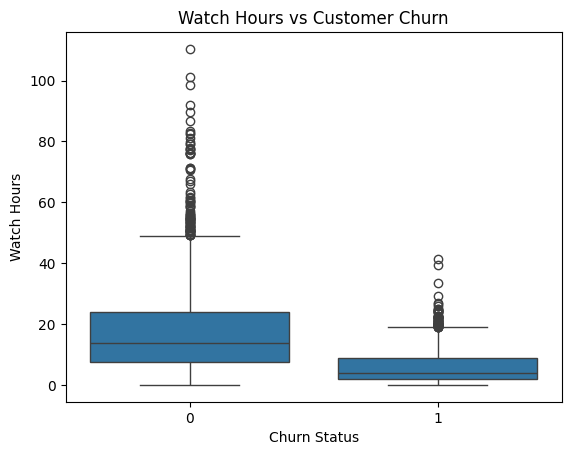

In [ ]:
sns.boxplot(
    data=df,
    x="churned",
    y="watch_hours"
)

plt.title("Watch Hours vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Watch Hours")

plt.show()

In [ ]:
df.groupby("churned")["watch_hours"].mean()

,watch_hours
churned,
0,17.449590
1,5.918497


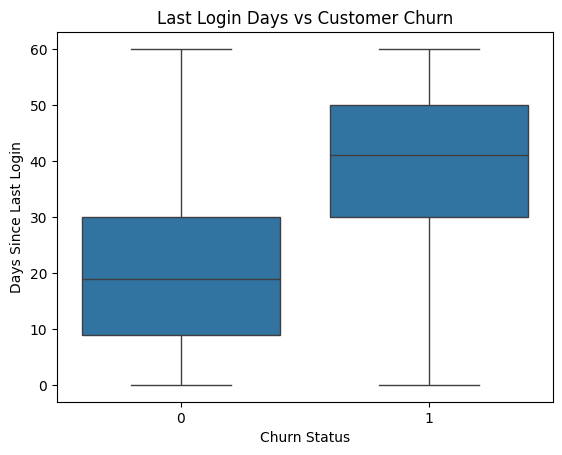

In [ ]:
sns.boxplot(
    data=df,
    x="churned",
    y="last_login_days"
)

plt.title("Last Login Days vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Days Since Last Login")

plt.show()

In [ ]:
df.groupby("churned")["last_login_days"].mean()

,last_login_days
churned,
0,21.771026
1,38.309344


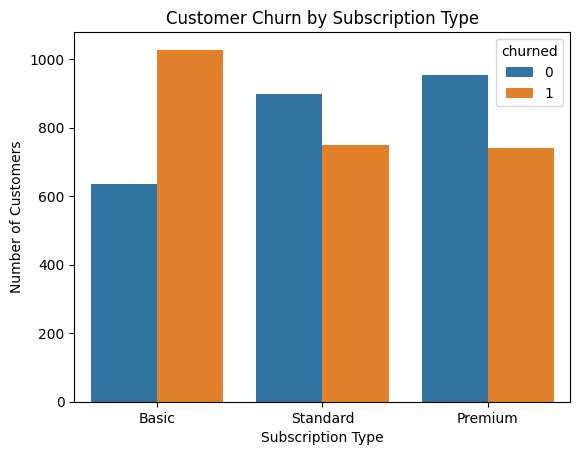

In [ ]:
sns.countplot(
    data=df,
    x="subscription_type",
    hue="churned"
)

plt.title("Customer Churn by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
df.groupby("subscription_type")["churned"].mean() * 100

,churned
subscription_type,
Basic,61.830223
Premium,43.709392
Standard,45.443499


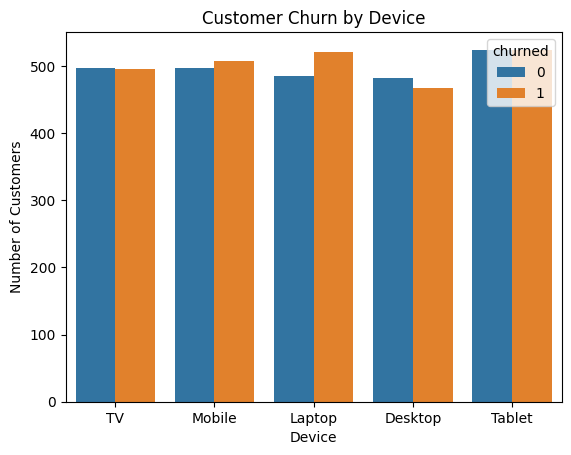

In [ ]:
sns.countplot(
    data=df,
    x="device",
    hue="churned"
)

plt.title("Customer Churn by Device")
plt.xlabel("Device")
plt.ylabel("Number of Customers")

plt.show()

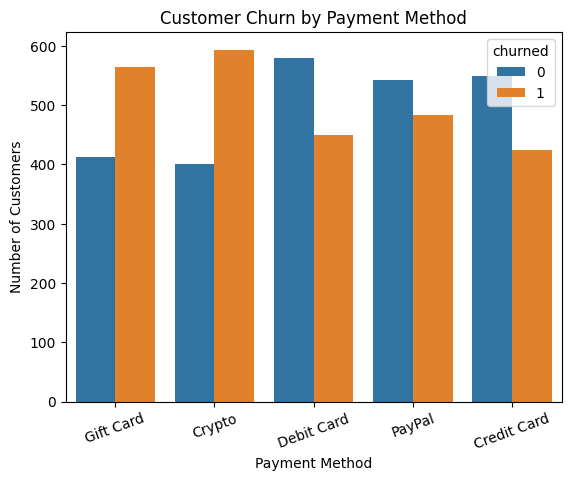

In [ ]:
sns.countplot(
    data=df,
    x="payment_method",
    hue="churned"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

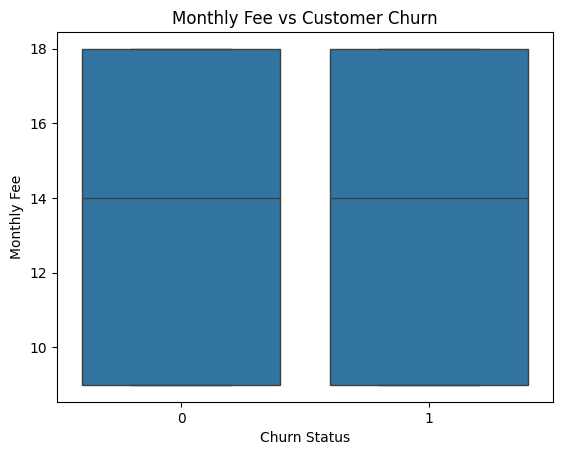

In [ ]:
sns.boxplot(
    data=df,
    x="churned",
    y="monthly_fee"
)

plt.title("Monthly Fee vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Fee")

plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

numeric_df.corr()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
age,1.000000,0.031539,0.016769,-0.013943,-0.003515,0.017333,0.010355
watch_hours,0.031539,1.000000,0.001697,0.004960,-0.479916,0.016528,0.349742
last_login_days,0.016769,0.001697,1.000000,-0.000789,0.471590,0.017242,-0.338418
monthly_fee,-0.013943,0.004960,-0.000789,1.000000,-0.152117,0.021905,-0.010401
churned,-0.003515,-0.479916,0.471590,-0.152117,1.000000,-0.158614,-0.272958
number_of_profiles,0.017333,0.016528,0.017242,0.021905,-0.158614,1.000000,-0.001246
avg_watch_time_per_day,0.010355,0.349742,-0.338418,-0.010401,-0.272958,-0.001246,1.000000


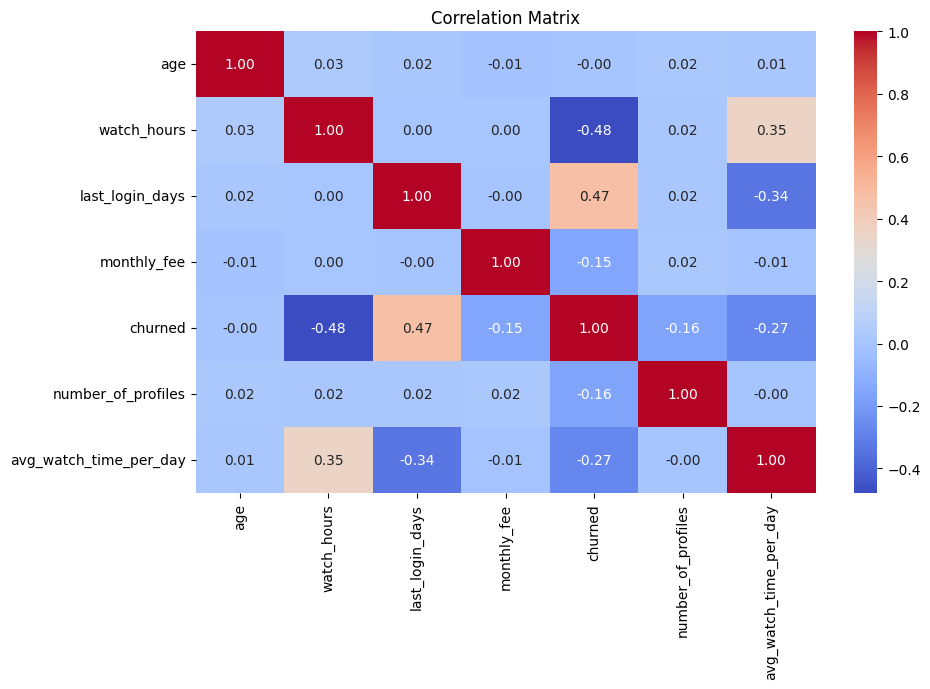

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

3. Machine Learning

In [ ]:
X = df.drop(columns=["customer_id", "churned"])

y = df["churned"]

In [ ]:
numeric_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print("Numeric columns:")
print(numeric_columns)

print()

print("Categorical columns:")
print(categorical_columns)

Numeric columns:
Index(['age', 'watch_hours', 'last_login_days', 'monthly_fee',
       'number_of_profiles', 'avg_watch_time_per_day'],
      dtype='object')

Categorical columns:
Index(['gender', 'subscription_type', 'region', 'device', 'payment_method',
       'favorite_genre'],
      dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_columns
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ]
)

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 12)
Testing data: (1000, 12)


In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'watch_hours', 'last_login_days', 'monthly_fee',
       'number_of_profiles', 'avg_watch_time_per_day'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'subscription_type', 'region', 'device', 'payment_method',
       'favorite_genre'],
      dtype='object'))])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_probability = model.predict_proba(X_test)[:, 1]

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.887


In [ ]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.90      0.87      0.88       497
           1       0.88      0.90      0.89       503

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000



In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[432  65]
 [ 48 455]]


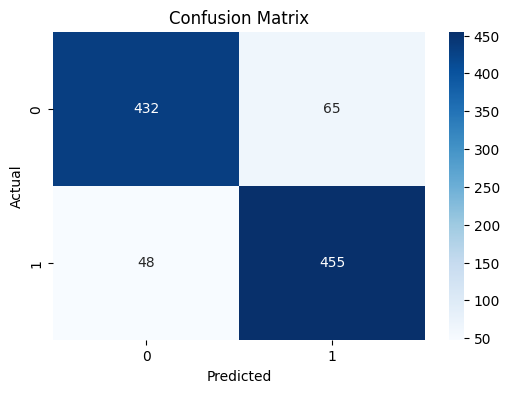

In [ ]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC AUC:", auc)

ROC AUC: 0.9658787716357788


Thank You